## Import libraries

In [1]:
# Import libraries for matrix and vector computation
import numpy as np
from numpy.linalg import norm
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import pygmt as pmt # for plotting

## Load station list

In [2]:
station_list=pd.read_csv("/home/msseo/works/19.Korea_Directivity/49.251008_Okcheon/1.HypoInv/STA/Okcheon.sta", sep=',', names=["Networkcode", "Latitude", "Longitude", "Elevation", "Weight"])
station_list.head()

,Networkcode,Latitude,Longitude,Elevation,Weight
0,KS.ADOA,36.572701,128.700897,0.0,100.0
1,KS.AGSA,37.091702,127.808098,0.0,100.0
2,KS.ASNA,36.827702,127.012299,0.0,100.0
3,KS.BLGA,36.139198,127.303200,0.0,100.0
4,KS.BOGA,37.013199,127.329399,0.0,100.0


## Plot epicenters 

### `Kim et al. (2011)`

#### Load location results

In [3]:
kim2011_result=pd.read_csv("/home/msseo/works/19.Korea_Directivity/49.251008_Okcheon/1.HypoInv/kim2011/Okcheon.sum", sep=',')
kim2011_result[["   DATE     TIME", " SEC ", "   LAT  ", "   LON   ", " DEPTH", "NUM", "GAP", " DMIN", " RMS ", "  ERH", "  ERZ"]].head()

,DATE TIME,SEC,LAT,LON,DEPTH,NUM,GAP,DMIN,RMS,ERH,ERZ
0,2022/11/16 12:32,41.03,36.2822,127.7598,9.75,72,26,7.7,0.05,0.1,0.4
1,2024/01/03 18:28,11.60,36.2828,127.7601,9.80,93,17,7.7,0.07,0.1,0.3
2,2024/01/03 18:52,50.13,36.2820,127.7602,9.70,39,38,7.7,0.05,0.2,0.5
3,2024/12/27 21:22,8.52,36.2824,127.7601,9.71,88,17,7.7,0.06,0.1,0.3
4,2025/04/19 10:17,15.02,36.2828,127.7601,9.73,66,27,7.7,0.06,0.1,0.4


#### Plot

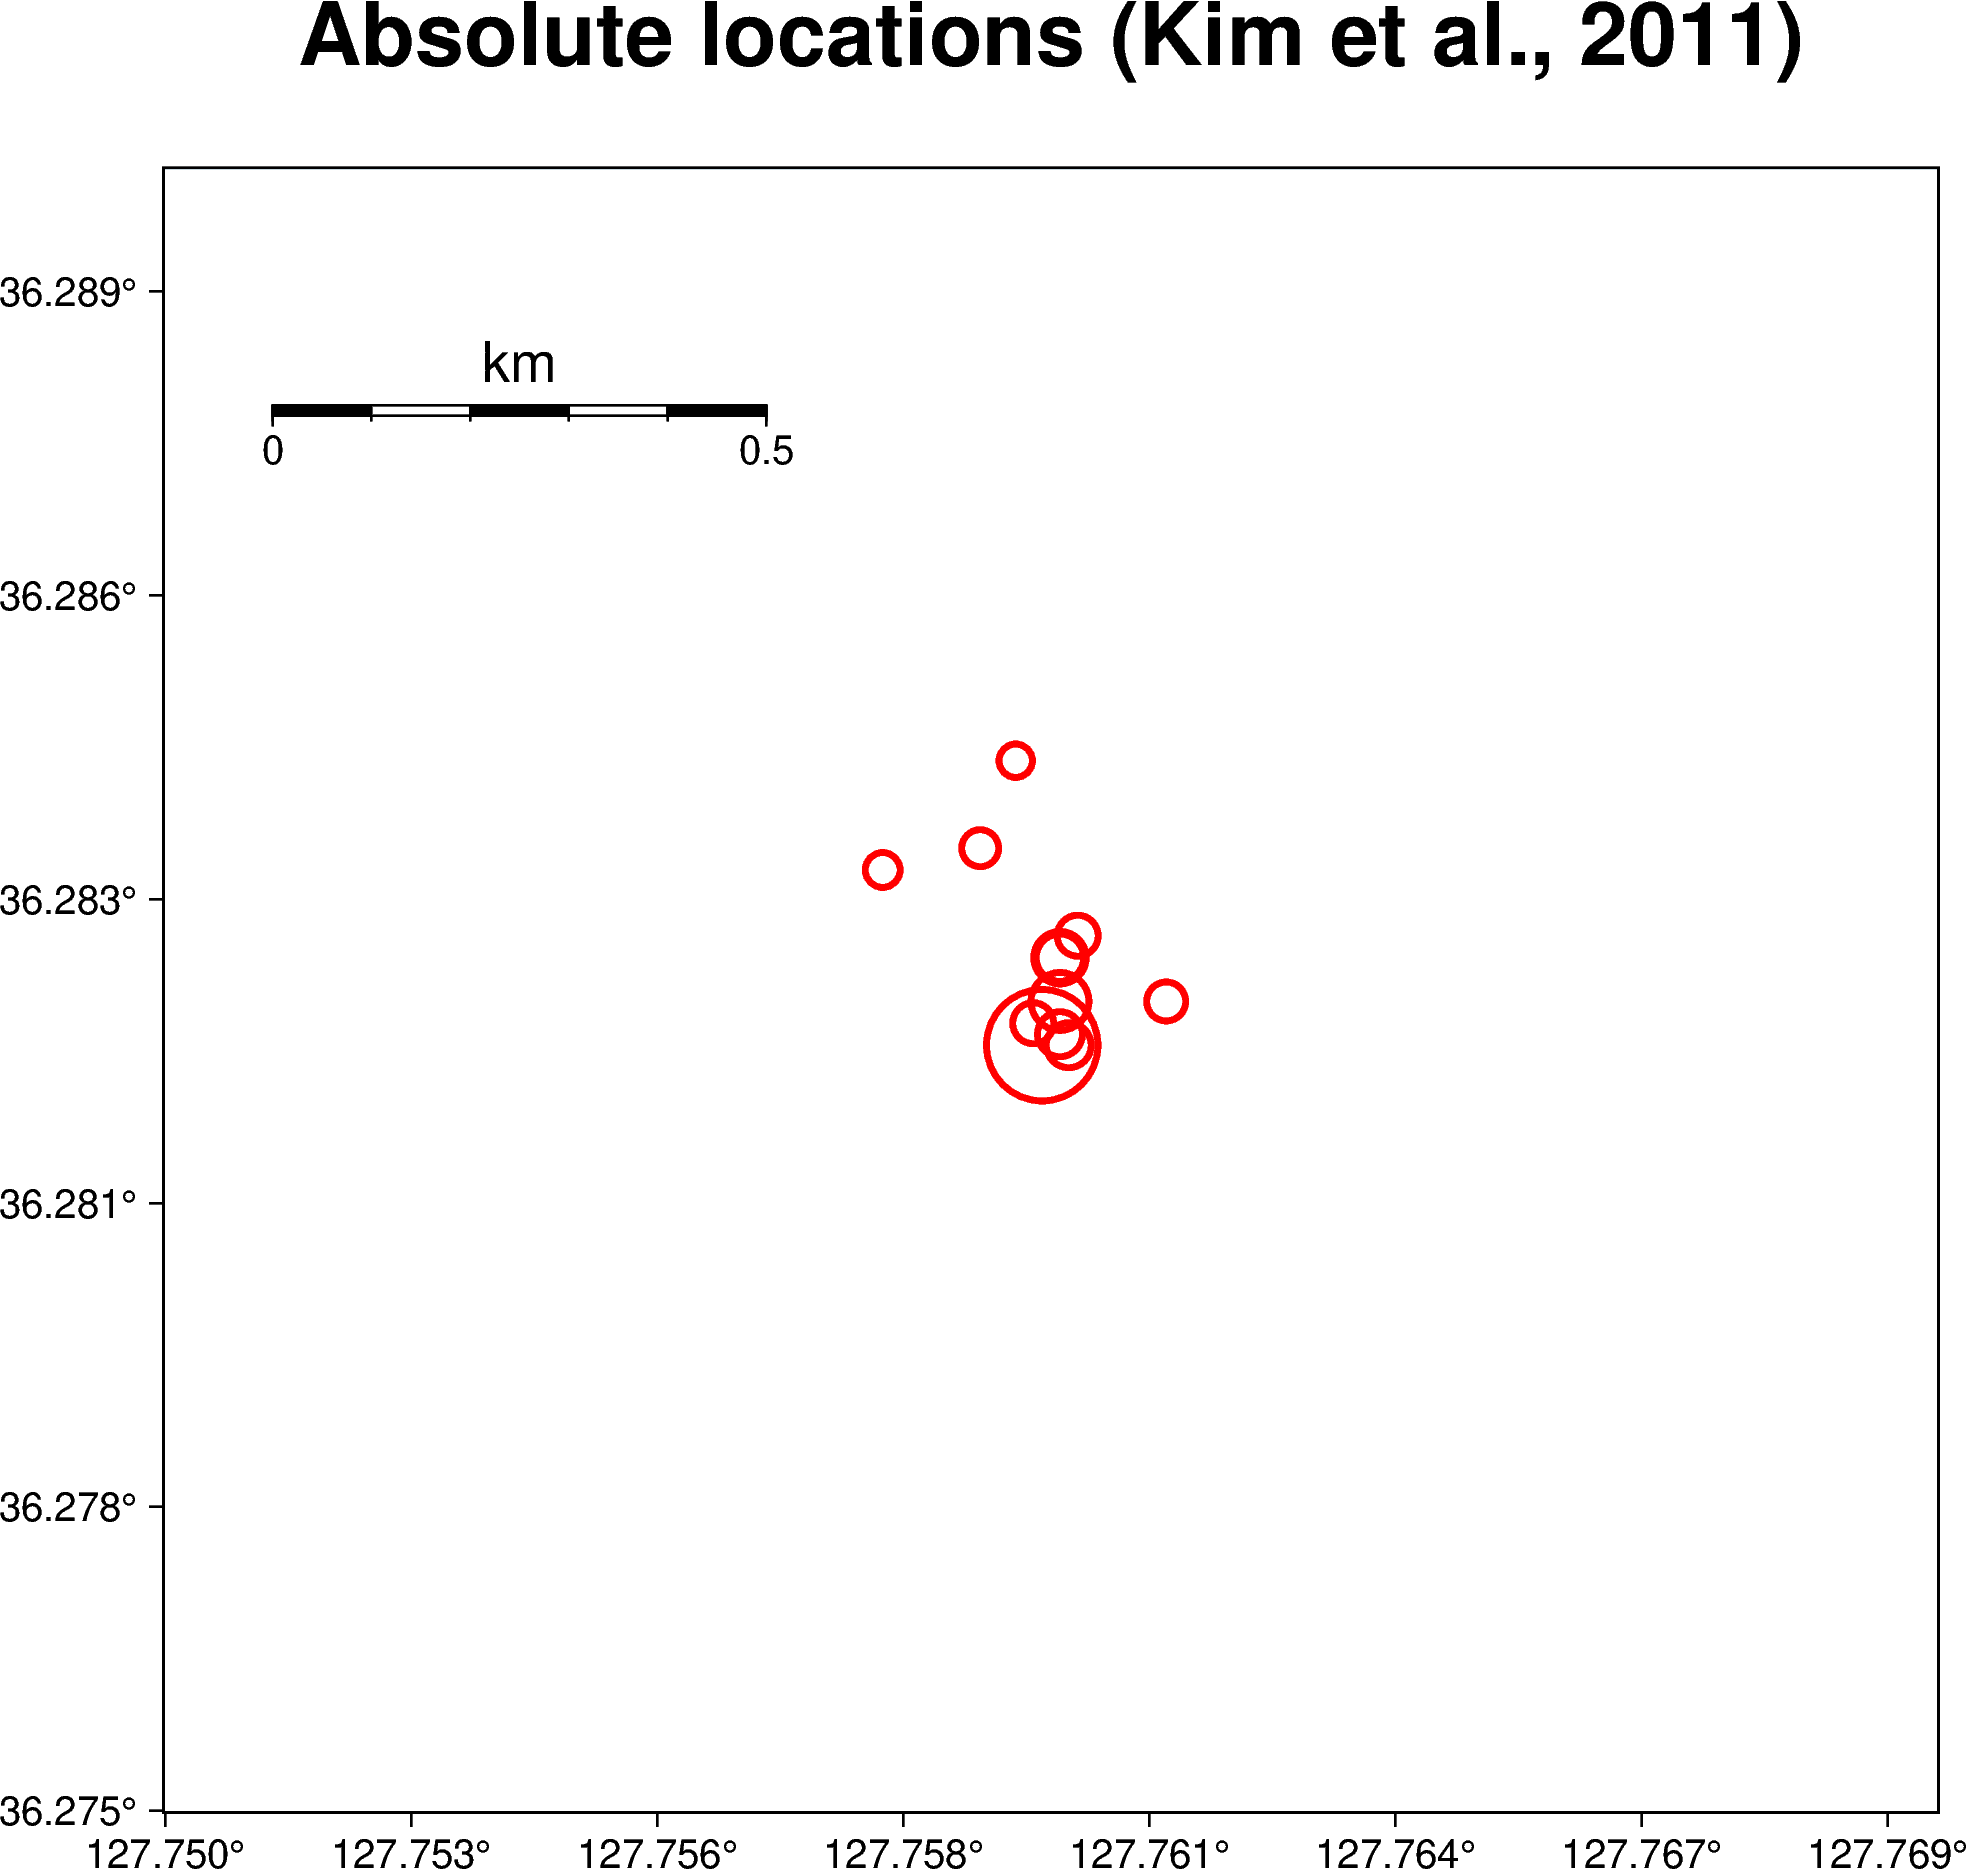

In [4]:
fig=pmt.Figure()
pmt.config(FORMAT_GEO_MAP="ddd.xxx", MAP_FRAME_TYPE="plain") # Use decimal degrees for latitude/longitude

region=[127.75, 127.77, 36.275, 36.29]

fig.basemap(region=region, projection="M15c", frame=["a", '+t"Absolute locations (Kim et al., 2011)"'])
fig.coast(land="white", water="skyblue" ,shorelines=True, map_scale="n0.2/0.85+f+l+c127.75/36.32+w0.5")

mag_list=[1.1, 1.4, 1.3, 1.8, 1.6, 3.1, 0.9, 0.8, 0.7, 1.1, 1.3, 1.0]

# Plot epicenters
for i in range(len(kim2011_result)):
    year=int(kim2011_result["   DATE     TIME"][i].split("/")[0])
    csize=0.2*np.exp(0.5*mag_list[i])
    fig.plot(x=kim2011_result["   LON   "][i], y=kim2011_result["   LAT  "][i], style=f"c{csize}c", pen="1.5p,red")
        
# Plot stations (in North Korea)
for i in range(len(station_list)):
    fig.plot(x=station_list["Longitude"][i], y=station_list["Latitude"][i], style="s0.5c", fill="blue", pen="1.0p,black")
    fig.text(x=station_list["Longitude"][i], y=station_list["Latitude"][i]-0.01, text=f"{station_list['Networkcode'][i][3:]}", font="15p")

# with pmt.config(FONT_ANNOT_PRIMARY="18p"):
#     fig.legend(position="JBL+jBL+o0.2c", box='+gwhite+p1p')
    
fig.show(width=500)
# fig.savefig("./Figures/Kim2011_all_events.pdf", dpi=500)

### `Kim & Kim (1983)`

#### Load location results

In [5]:
kim1983_result=pd.read_csv("/home/msseo/works/19.Korea_Directivity/49.251008_Okcheon/1.HypoInv/kim1983/Okcheon.sum", sep=',')
kim1983_result[["   DATE     TIME", " SEC ", "   LAT  ", "   LON   ", " DEPTH", "NUM", "GAP", " DMIN", " RMS ", "  ERH", "  ERZ"]].head()

,DATE TIME,SEC,LAT,LON,DEPTH,NUM,GAP,DMIN,RMS,ERH,ERZ
0,2022/11/16 12:32,41.15,36.2823,127.7609,8.63,55,32,7.7,0.14,0.2,0.5
1,2024/01/03 18:28,11.73,36.2836,127.7610,8.81,69,17,7.6,0.11,0.2,0.4
2,2024/01/03 18:52,50.28,36.2841,127.7597,8.55,35,43,7.6,0.13,0.3,0.7
3,2024/12/27 21:22,8.65,36.2815,127.7609,8.63,68,19,7.8,0.13,0.2,0.5
4,2025/04/19 10:17,15.16,36.2832,127.7609,8.69,50,32,7.6,0.11,0.2,0.5


#### Plot

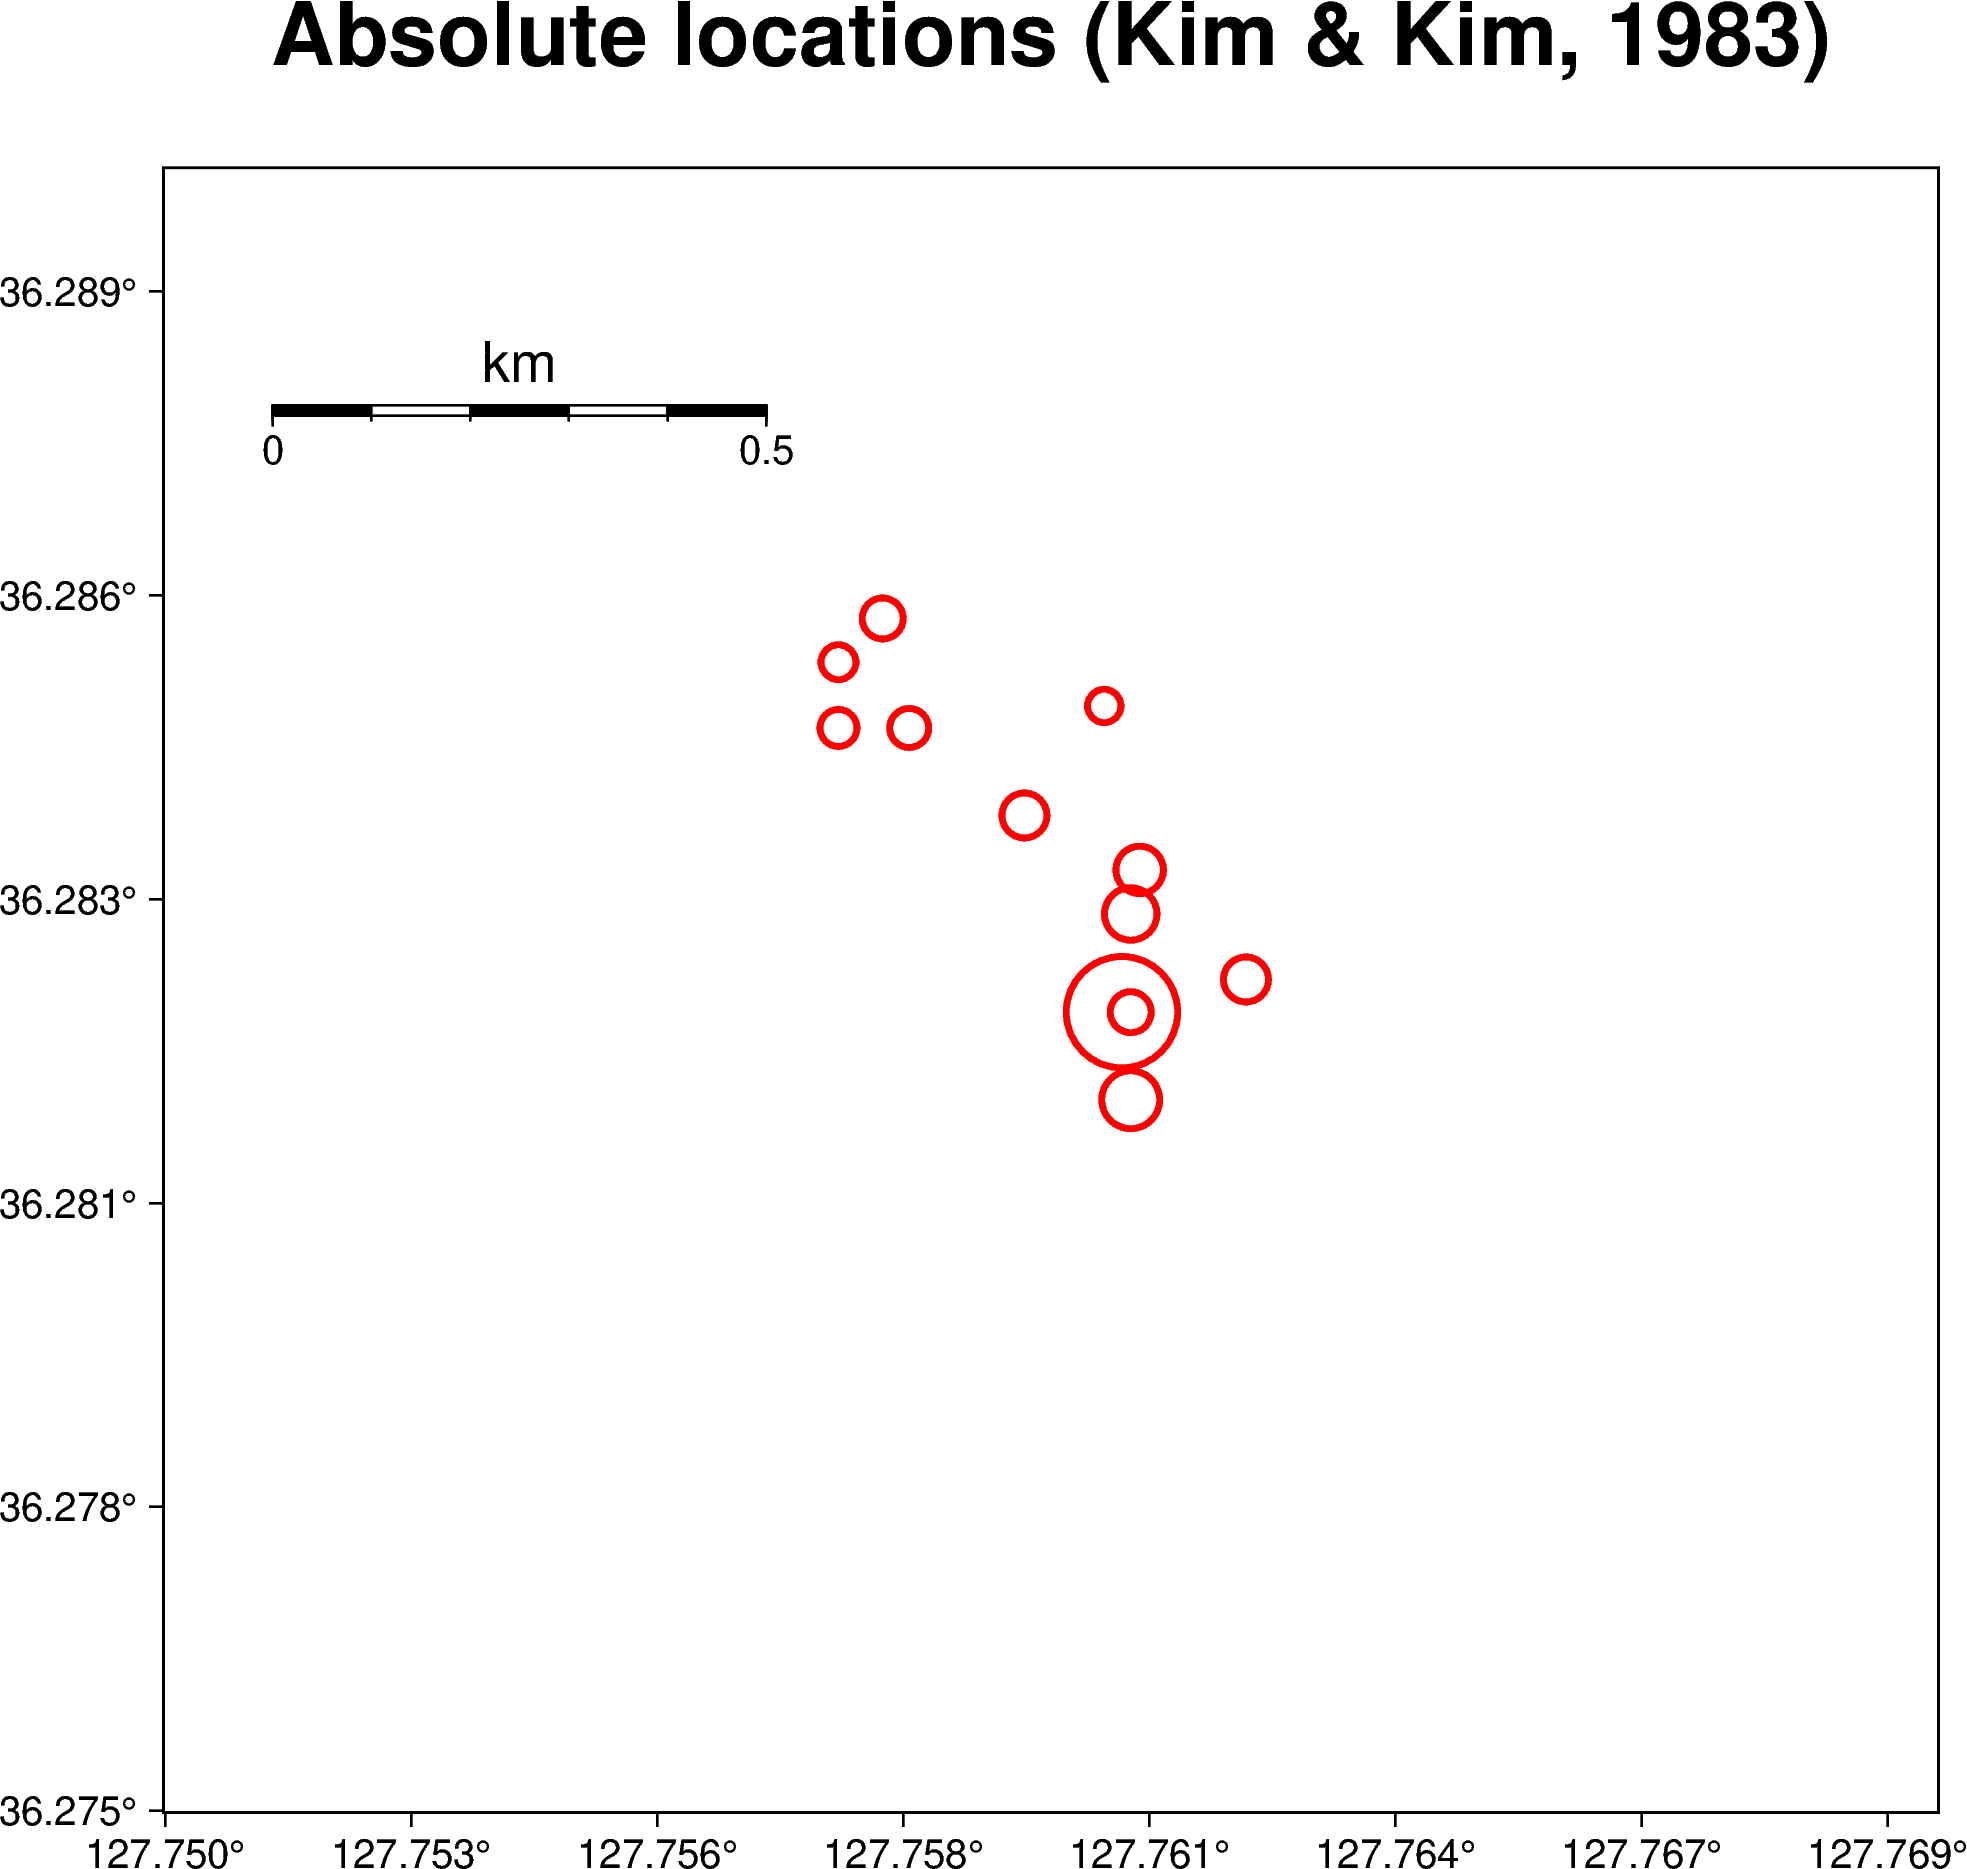

In [6]:
fig=pmt.Figure()
pmt.config(FORMAT_GEO_MAP="ddd.xxx", MAP_FRAME_TYPE="plain") # Use decimal degrees for latitude/longitude

region=[127.75, 127.77, 36.275, 36.29]

fig.basemap(region=region, projection="M15c", frame=["a", '+t"Absolute locations (Kim & Kim, 1983)"'])
fig.coast(land="white", water="skyblue" ,shorelines=True, map_scale="n0.2/0.85+f+l+c127.75/36.32+w0.5")

mag_list=[1.1, 1.4, 1.3, 1.8, 1.6, 3.1, 0.9, 0.8, 0.7, 1.1, 1.3, 1.0]

# Plot epicenters
for i in range(len(kim1983_result)):
    year=int(kim1983_result["   DATE     TIME"][i].split("/")[0])
    csize=0.2*np.exp(0.5*mag_list[i])
    fig.plot(x=kim1983_result["   LON   "][i], y=kim1983_result["   LAT  "][i], style=f"c{csize}c", pen="1.5p,red")
        
# Plot stations (in North Korea)
for i in range(len(station_list)):
    fig.plot(x=station_list["Longitude"][i], y=station_list["Latitude"][i], style="s0.5c", fill="blue", pen="1.0p,black")
    fig.text(x=station_list["Longitude"][i], y=station_list["Latitude"][i]-0.01, text=f"{station_list['Networkcode'][i][3:]}", font="15p")

# with pmt.config(FONT_ANNOT_PRIMARY="18p"):
#     fig.legend(position="JBL+jBL+o0.2c", box='+gwhite+p1p')
    
fig.show(width=500)
# fig.savefig("./Figures/Kim2011_all_events.pdf", dpi=500)